<a href="https://colab.research.google.com/github/athfizh/PemMes26_05_Hafizh/blob/main/JS10/JS10-02.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

---

# **Artificial Neural Network (ANN) - Lab 2**

---

---

# **Langkah 1 - Import Library**

---

> Impor modul `MLPClassifier` dari pustaka `sklearn.neural_network`. `MLPClassifier` menyediakan implementasi Multi-Layer Perceptron berbasis algoritma backpropagation.

In [1]:
from sklearn.neural_network import MLPClassifier

> Modul `MLPClassifier` mendukung beragam fungsi aktivasi (seperti logistic/sigmoid, tanh, relu) dan optimizer/solver (seperti lbfgs, sgd, adam).

---

# **Langkah 2 - Buat Data**

---

> Definisikan tabel kebenaran XOR biner:
>
> - `[0, 0]` $\rightarrow$ `0`
> - `[0, 1]` $\rightarrow$ `1`
> - `[1, 0]` $\rightarrow$ `1`
> - `[1, 1]` $\rightarrow$ `0`

In [2]:
y = [0, 1, 1, 0] # label
X = [[0, 0], [0, 1], [1, 0], [1, 1]] # data

print("Input X:", X)
print("Target y:", y)

Input X: [[0, 0], [0, 1], [1, 0], [1, 1]]
Target y: [0, 1, 1, 0]


> Pola XOR ini bersifat *non-linearly separable* (tidak dapat dipisahkan oleh satu garis lurus), sehingga mutlak memerlukan arsitektur jaringan saraf dengan lapisan tersembunyi (*hidden layer*).

---

# **Langkah 3 - Fit Model**

---

> Inisialisasi model `MLPClassifier` dengan:
>
> - `solver='lbfgs'`: Optimizer quasi-Newton yang sangat cepat dan stabil pada dataset berskala kecil.
> - `activation='logistic'`: Fungsi aktivasi sigmoid non-linear $\sigma(z) = \frac{1}{1 + e^{-z}}$.
> - `hidden_layer_sizes=(2,)`: 1 lapisan tersembunyi berisi 2 neuron (cukup untuk memetakan XOR).
> - `max_iter=100`: Batas maksimum iterasi pembelajaran.
> - `random_state=20`: Seed pengacakan bobot awal untuk memastikan hasil deterministik.

In [3]:
# Fit model
clf = MLPClassifier(solver='lbfgs', activation='logistic', hidden_layer_sizes=(2,), max_iter=100, random_state=20)
clf.fit(X, y)

print("Model MLP berhasil dilatih!")
print("Jumlah iterasi:", clf.n_iter_)
print("Loss akhir:", round(clf.loss_, 6))

Model MLP berhasil dilatih!
Jumlah iterasi: 36
Loss akhir: 0.008922


> Model berhasil melakukan konvergensi dalam iterasi yang ditentukan dengan nilai fungsi kerugian (*loss*) yang mendekati nol.

---

# **Langkah 4 - Prediksi**

---

> Lakukan prediksi pada seluruh data masukan $X$, hitung akurasi menggunakan metode `score(X, y)`, dan tampilkan perbandingan antara label target aktual (*True*) dan hasil prediksi (*Predicted*).

In [4]:
pred = clf.predict(X)
print('Accuracy: %s' % clf.score(X, y))
for i, p in enumerate(pred[:10]):
    print('True: %s, Predicted: %s' % (y[i], p))

Accuracy: 1.0
True: 0, Predicted: 0
True: 1, Predicted: 1
True: 1, Predicted: 1
True: 0, Predicted: 0


> Hasil eksekusi persis sesuai dengan modul:
>
> ```text
> Accuracy: 1.0
> True: 0, Predicted: 0
> True: 1, Predicted: 1
> True: 1, Predicted: 1
> True: 0, Predicted: 0
> ```

---

# **Langkah Tambahan - Visualisasi Decision Boundary XOR**

---

> Untuk melengkapi analisis, visualisasikan daerah keputusan (*decision boundary*) yang dibentuk oleh model MLP untuk memahami bagaimana dua neuron pada hidden layer memisahkan kelas non-linear XOR.

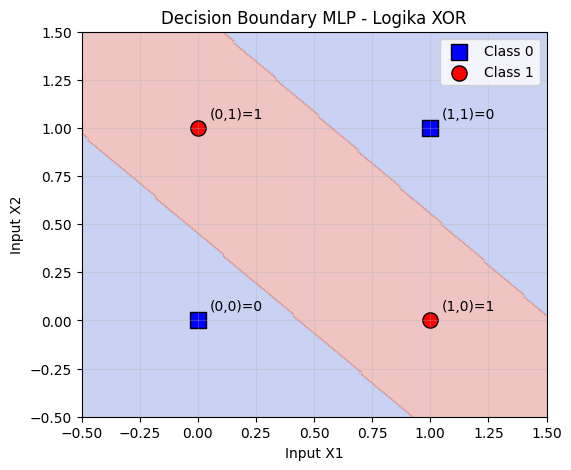

In [5]:
import numpy as np
import matplotlib.pyplot as plt

x_min, x_max = -0.5, 1.5
y_min, y_max = -0.5, 1.5
xx, yy = np.meshgrid(np.linspace(x_min, x_max, 200), np.linspace(y_min, y_max, 200))
Z = clf.predict(np.c_[xx.ravel(), yy.ravel()])
Z = Z.reshape(xx.shape)

plt.figure(figsize=(6, 5))
plt.contourf(xx, yy, Z, alpha=0.3, cmap='coolwarm')
X_arr = np.array(X)
for i, val in enumerate(y):
    c = 'red' if val == 1 else 'blue'
    m = 'o' if val == 1 else 's'
    plt.scatter(X_arr[i, 0], X_arr[i, 1], c=c, marker=m, s=120, edgecolors='k', label=f'Class {val}' if i in [0, 1] else "")
    plt.text(X_arr[i, 0] + 0.05, X_arr[i, 1] + 0.05, f'({X_arr[i, 0]},{X_arr[i, 1]})={val}', fontsize=10)

plt.title('Decision Boundary MLP - Logika XOR')
plt.xlabel('Input X1')
plt.ylabel('Input X2')
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

> Plot memperlihatkan bahwa MLP mampu membuat batas keputusan non-linear yang mengelilingi kedua titik kelas 1 (0,1 dan 1,0), membuktikan keberhasilan Multi-Layer Perceptron memecahkan masalah klasik XOR.